In [1]:
# If the import doesn't work, uncomment the following two lines, or "pip install thunor"
import os, sys
#sys.path.insert(0, os.path.abspath('../'))

import thunor
import json
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

from thunor.io import read_vanderbilt_hts
from thunor.dip import dip_rates
from thunor.curve_fit import fit_params
from thunor.curve_fit import fit_params_minimal
from thunor.plots import plot_drc, plot_drc_params, plot_time_course, plot_ctrl_dip_by_plate, plot_plate_map

In [2]:
hts007_file = 'C:\\Users\\olesk\\anaconda3\\envs\\ECM_model\\Lib\\site-packages\\thunor\\hts007.h5'


In [ ]:
hts007.controls

In [4]:
f = open('C:\\Users\\olesk\\ECM_mod_output\\cell_counts_di_4kpa_erl.json')
cell_counts_di_4erl = json.load(f)

In [5]:
f = open('C:\\Users\\olesk\\ECM_mod_output\\cell_counts_di_55kpa_erl2.json')
cell_counts_di_55erl = json.load(f)

In [6]:
EXPT_ID = 1
EXPT_DATE = '2023-11-21'
PLATE_NAME = 'test'
CELL_LINE = 'DS8'
DRUG1 = 'cycdi'
DRUG1_UNITS = 'M'
UPID = 'test'
df_columns = ['expt.id', 'expt.date', 'plate.name', 'well', 'cell.line', 'time', 'drug1', 'drug1.conc', 'drug1.units', 'cell.count', 'upid']


In [7]:
WELLS = ['A01', 'A02', 'A03', 'A04', 'A05', 'B01', 'B02', 'B03', 'B04', 'B05', 
         'C01', 'C02', 'C03', 'A04', 'A05', 'A01', 'A02', 'A03', 'A04', 'A05', 
         'E01', 'E02', 'E03', 'A04', 'A05', 'A01', 'A02', 'A03', 'A04', 'A05', 
         'G01', 'G02', 'G03', 'A04', 'A05', 'A01', 'A02', 'A03', 'A04', 'A05',
         'I01', 'I02', 'I03', 'A04', 'A05', 'A01', 'A02', 'A03', 'A04', 'A05', 
         'K01', 'K02', 'K03', 'A04', 'A05', 'A01', 'A02', 'A03', 'A04', 'A05', 
         'M01', 'M02', 'M03', 'A04', 'A05',]


In [37]:
WELLS = []
for c in list(map(chr,range(ord('A'),ord('M')+1))):
    tmp_lst = [c+"{:02d}".format(num) for num in range(1,6)]
    WELLS.append(tmp_lst)
WELLS = [x for xs in WELLS for x in xs]

In [8]:
all_treats = pd.DataFrame(columns = df_columns)


In [9]:
def add_cond(allDF, cell_counts, drug="drug1"):
    n=0
    for cond in cell_counts:
        for run in cell_counts[cond]:
            tmp_t = [point[0] for point in run]
            tmp_c = [point[1] for point in run]
            
            tmp_dict = {'expt.id': [EXPT_ID] * len(tmp_t),
                        'expt.date': [EXPT_DATE] * len(tmp_t),
                        'plate.name': [PLATE_NAME] * len(tmp_t),
                        'well': [WELLS[n]] * len(tmp_t),
                        'cell.line': [CELL_LINE] * len(tmp_t),
                        'time': tmp_t,
                        'drug1': [drug] * len(tmp_t),
                        'drug1.conc': [float(cond)*10e-7] * len(tmp_t),
                        'drug1.units': [DRUG1_UNITS] * len(tmp_t),
                        'cell.count': tmp_c,
                        'upid': [UPID] * len(tmp_t)
                       }
            tmp_df = pd.DataFrame(tmp_dict)
            df_r = tmp_df.loc[tmp_df['time'] <= 120]
            df_r = df_r.round({'time': 3})
            df_r = df_r.drop_duplicates(subset=['time'])
            
            n+=1
            allDF = pd.concat([allDF, df_r], ignore_index=True)
    return allDF
    
            

In [10]:
def calc_resp(filepath, drug, wells=WELLS):
    f = open(filepath)
    cell_counts = json.load(f)
    name = filepath.split('\\')[-1].split('.')[0].split('_')[2:]

    EXPT_ID = 1
    EXPT_DATE = '2023-11-21'
    PLATE_NAME = 'test'
    CELL_LINE = 'DS8'
    DRUG1 = 'cycdi'
    DRUG1_UNITS = 'M'
    UPID = 'test'
    df_columns = ['expt.id', 'expt.date', 'plate.name', 'well', 'cell.line', 'time', 'drug1', 'drug1.conc', 'drug1.units', 'cell.count', 'upid']

    all_treats = pd.DataFrame(columns = df_columns)
    
    all_treats = add_cond(all_treats, cell_counts, drug=drug)
    name_c = '_'.join(name)
    all_treats.to_csv('C:\\Users\\olesk\\ECM_mod_output\\'+name_c+'.csv', index=False)
    
    hts = read_vanderbilt_hts('C:\\Users\\olesk\\ECM_mod_output\\'+name_c+'.csv')
    
    ctrl_dip_data, expt_dip_data = dip_rates(hts)
    fp = fit_params(ctrl_dip_data, expt_dip_data)
    return fp, ctrl_dip_data, expt_dip_data

In [11]:
cell_counts_di_55erl.keys()

dict_keys(['0', '0.001', '0.01', '0.025', '0.05', '0.1', '0.2', '0.3', '0.4', '0.5', '1', '2', '5'])

In [12]:
def add_plot(cell_count, run_time, fig, ax, title="Unknown condition", color="black", ls='-'):
    t_sim = np.arange(0, run_time, 1 / 3)
    cell_count_t = np.zeros(len(t_sim))
    time_tmp_m = 0
    for time_tmp_p, cell_count_time_tmp in cell_count:
        cell_count_t[(time_tmp_m <= t_sim) & (t_sim < time_tmp_p)] = cell_count_time_tmp
        time_tmp_m = time_tmp_p
    pop_dubs = np.log2(cell_count_t / cell_count_t[0])
    ax.plot(t_sim, pop_dubs, color=color, lw=1, alpha=0.8, ls=ls)

    return

In [13]:
def make_fig(cell_count, run_time, title="Unknown condition"):
    fig, ax = plt.subplots()
    
    ax.set_xlabel('Time (h)')
    ax.set_ylabel('Population doublings')
    ax.set_ylim(0,5)
    plt.text(0,4.5,title)
    
    return fig, ax

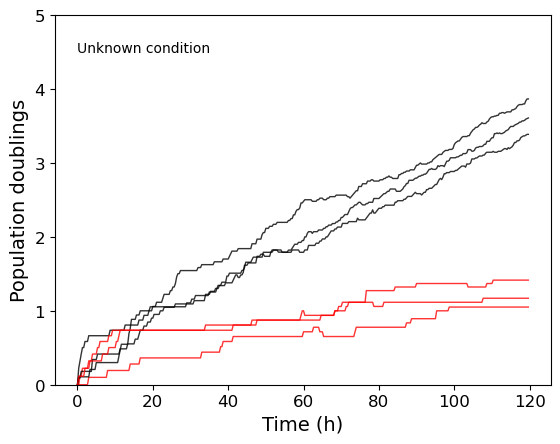

In [26]:
fig,ax = make_fig(cell_counts_di_55erl['0'][0], 120, title="Unknown condition")
for ii in range(3):
    add_plot(cell_counts_di_55erl['0'][ii], 120, fig, ax, title="Unknown condition", color="black")
#     add_plot(cell_counts_di_55erl['0.1'][ii], 120, fig, ax, title="Unknown condition", color="blue")
    add_plot(cell_counts_di_55erl['0.4'][ii], 120, fig, ax, title="Unknown condition", color="red")
    

In [16]:
from pathlib import Path
from scipy.signal import savgol_filter
import re
import math
SAVEFILES = False
OVERWRITE = True

SAVEDIR = Path(os.path.expanduser("~/ECM_mod_output"))
if not os.path.exists(SAVEDIR) and SAVEFILES:
    os.mkdir(SAVEDIR)

    
DATADIR = "C:\\Users\\olesk\\ECM_mod_output"


In [17]:
filepaths = os.listdir(DATADIR)
filenames = [f for f in filepaths if re.search('^cell_counts.*csv$', f)]
filepaths = [Path(DATADIR, f) for f in filenames]
filepaths.sort()

In [18]:
def calc_doub(filename):
    tmp = np.loadtxt(filename, delimiter=',')
    
    t = np.arange(0,121)
    new_r = []
    for num in t:
        vals = tmp[tmp[:,0]<=num]
        new_r.append([num, vals[-1,1]])
    
    doubs = []
    for num in t:
        doub = math.log(new_r[num][1]/new_r[0][1])/math.log(2)
        doubs.append([num, doub])
        
    return doubs
    

In [19]:
all_doubs = pd.DataFrame(columns=['Condition','Time','Doub'])
for filename in filepaths:
    doub = calc_doub(filename)
    tmp = [x[1] for x in doub]
    
    split_n = str(filename).split('\\')
    name = split_n[-1].split('.c')[0]
    
    t = np.arange(0,121)
    data = {
        'Condition': [name]*len(t), 
        'Time': t,
        'Doub': tmp}
    tmp_df = pd.DataFrame(data)
    
    all_doubs = pd.concat([all_doubs, tmp_df], ignore_index=True)
    


In [20]:
doub_arr = np.zeros((121,18))
n = 0
for filename in filepaths:
    
    split_n = str(filename).split('\\')
    name = split_n[-1].split('.c')[0]
    
    tmp = all_doubs.loc[all_doubs['Condition'] == name]
    doub_arr[:,n]=tmp['Doub']
    n+=1

    

In [21]:
means=[np.mean(doub_arr[:,0:2],axis=1), np.mean(doub_arr[:,3:5],axis=1), np.mean(doub_arr[:,6:8],axis=1), 
       np.mean(doub_arr[:,9:11],axis=1), np.mean(doub_arr[:,12:14],axis=1), np.mean(doub_arr[:,15:17],axis=1)]
    
stdevs=[np.std(doub_arr[:,0:2],axis=1), np.std(doub_arr[:,3:5],axis=1), np.std(doub_arr[:,6:8],axis=1), 
       np.std(doub_arr[:,9:11],axis=1), np.std(doub_arr[:,12:14],axis=1), np.std(doub_arr[:,15:17],axis=1)]


In [34]:
run_time = 120
all_doubs = np.zeros((360,3))
for ii in range(3):
    cell_count = cell_counts_di_55erl['0.4'][ii]
    t_sim = np.arange(0, run_time, 1 / 3)
    cell_count_t = np.zeros(len(t_sim))
    time_tmp_m = 0
    for time_tmp_p, cell_count_time_tmp in cell_count:
        cell_count_t[(time_tmp_m <= t_sim) & (t_sim < time_tmp_p)] = cell_count_time_tmp
        time_tmp_m = time_tmp_p
    pop_dubs = np.log2(cell_count_t / cell_count_t[0])
    all_doubs[:,ii] = pop_dubs



In [35]:
mean_treat = np.mean(all_doubs, axis=1)
std_treat = np.std(all_doubs, axis=1)

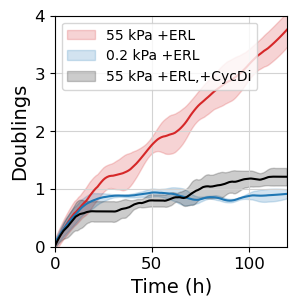

In [36]:
win = 21
pol = 2
size = (3,3)
c1 = "tab:blue"
c2 = "tab:red"
xmin = 0
xmax = 120
ymin = 0
ymax = 4

params = {'axes.titley': 1,
         'axes.titlepad': 5,
         'axes.labelsize': 14,
         'axes.edgecolor': "black",
         'axes.titlesize': 18,
         'xtick.labelsize': 12,
         'ytick.labelsize': 12}
plt.rcParams.update(params)

fig, axes = plt.subplots(1, 1, figsize=size)

t = np.arange(0,121)
t1 = np.arange(0, run_time, 1 / 3)
axes.plot(t, savgol_filter(means[5],win,pol), color=c2)
axes.fill_between(t, savgol_filter(means[5] - stdevs[5],win,pol), 
                     savgol_filter(means[5] + stdevs[5],win,pol), color=c2, alpha=0.2, label='55 kPa +ERL')

axes.plot(t, savgol_filter(means[1],win,pol), color=c1)
axes.fill_between(t, savgol_filter(means[1] - stdevs[1],win,pol),
                     savgol_filter(means[1] + stdevs[1],win,pol), color=c1, alpha=0.2, label='0.2 kPa +ERL')

axes.plot(t1, savgol_filter(mean_treat,win,pol), color='black')
axes.fill_between(t1, savgol_filter(mean_treat - std_treat,win,pol),
                     savgol_filter(mean_treat + std_treat,win,pol), color='black', alpha=0.2, label='55 kPa +ERL,+CycDi')


axes.set_xlim([xmin, xmax])
axes.set_ylim([ymin, ymax])

axes.set_xticks([0,50,100])
axes.set_yticks([0,1,2,3,4])
axes.grid(color='lightgray')
axes.set_xlabel('Time (h)')
axes.set_ylabel('Doublings')

axes.legend()



In [38]:

add_plot(cell_counts_di['0'][0], 120, fig, ax, title="Unknown condition", color="black")

NameError: name 'cell_counts_di' is not defined

### CycDi 4kPa ERL

In [39]:
filepath = 'C:\\Users\\olesk\\ECM_mod_output\\cell_counts_di_55kpa_erl2.json'

In [40]:
fp, ctrl_dip_data, expt_dip_data = calc_resp(filepath, 'cycdi', wells=WELLS)

C:\Users\olesk\anaconda3\envs\ECM_model\lib\site-packages\thunor\curve_fit.py:157: RuntimeWarning: invalid value encountered in log
  return c + (d - c) / (1 + np.exp(b * (np.log(x) - np.log(e))))


In [42]:
df_params = fit_params_minimal(ctrl_dip_data, expt_dip_data)

C:\Users\olesk\anaconda3\envs\ECM_model\lib\site-packages\thunor\curve_fit.py:157: RuntimeWarning: invalid value encountered in log
  return c + (d - c) / (1 + np.exp(b * (np.log(x) - np.log(e))))


In [43]:
expt_dip_data

index plate  well_num  dip_rate  \
drug     cell_line dose       well_id                                      
(cycdi,) DS8       (1e-09,)   test__24       0  test        24  0.023579   
                              test__25     313  test        25  0.025346   
                              test__26     588  test        26  0.028439   
                              test__27     922  test        27  0.026924   
                              test__28    1241  test        28  0.025573   
                   (1e-08,)   test__48    1572  test        48  0.019671   
                              test__49    1817  test        49  0.025372   
                              test__50    2100  test        50  0.029452   
                              test__51    2432  test        51  0.026320   
                              test__52    2710  test        52  0.027877   
                   (2.5e-08,) test__72    3027  test        72  0.026340   
                              test__73    3264  test        73  0.024318   
                              test__74    3555  test        74  0.024265   
                              test__75    3812  test        75  0.024917   
                              test__76    4082  test        76  0.021826   
                   (5e-08,)   test__100   5279  test       100  0.023451   
                              test__96    4306  test        96  0.022383   
                              test__97    4550  test        97  0.024885   
                              test__98    4801  test        98  0.022178   
                              test__99    5061  test        99  0.024040   
                   (1e-07,)   test__120   5517  test       120  0.021836   
                              test__121   5734  test       121  0.018377   
                              test__122   5939  test       122  0.012598   
                              test__123   6105  test       123  0.010954   
                              test__124   6268  test       124  0.021101   
                   (2e-07,)   test__144   6480  test       144  0.010082   
                              test__145   6610  test       145  0.016145   
                              test__146   6765  test       146  0.006525   
                              test__147   6859  test       147  0.015086   
                              test__148   6986  test       148  0.010920   
                   (3e-07,)   test__168   7109  test       168  0.007461   
                              test__169   7190  test       169  0.005043   
                              test__170   7294  test       170  0.008562   
                              test__171   7374  test       171  0.009735   
                              test__172   7439  test       172  0.016055   
                   (4e-07,)   test__192   7516  test       192  0.007785   
                              test__193   7572  test       193  0.005484   
                              test__194   7631  test       194  0.008731   
                              test__195   7702  test       195  0.004592   
                              test__196   7756  test       196  0.006443   
                   (5e-07,)   test__216   7809  test       216  0.005645   
                              test__217   7845  test       217 -0.001419   
                              test__218   7895  test       218 -0.001886   
                              test__219   7939  test       219  0.005243   
                              test__220   7997  test       220  0.003961   
                   (1e-06,)   test__240   8033  test       240 -0.005626   
                              test__241   8040  test       241 -0.004456   
                              test__242   8047  test       242 -0.006471   
                              test__243   8055  test       243 -0.008514   
                              test__244   8064  test       244 -0.001329   
                   (2e-06,)   test__264   8070  test       264 -0.036190   
             

In [44]:
fp['ec50'].iloc[0]

2.5742338721348416e-07

In [45]:
fig = plot_drc(fp)

In [46]:
fig.data[0]

Scatter({
    'hoverinfo': 'all',
    'legendgroup': 'DS8\ncycdi',
    'line': {'color': 'rgb(246, 112, 136)', 'dash': 'solid', 'shape': 'spline', 'width': 3},
    'mode': 'lines',
    'name': 'DS8\ncycdi',
    'showlegend': False,
    'visible': True,
    'x': array([1.0e-10, 1.5e-10, 2.0e-10, 2.5e-10, 3.0e-10, 3.5e-10, 4.0e-10, 4.5e-10,
                5.0e-10, 5.5e-10, 6.0e-10, 6.5e-10, 7.0e-10, 7.5e-10, 8.0e-10, 8.5e-10,
                9.0e-10, 9.5e-10, 1.0e-09, 1.5e-09, 2.0e-09, 2.5e-09, 3.0e-09, 3.5e-09,
                4.0e-09, 4.5e-09, 5.0e-09, 5.5e-09, 6.0e-09, 6.5e-09, 7.0e-09, 7.5e-09,
                8.0e-09, 8.5e-09, 9.0e-09, 9.5e-09, 1.0e-08, 1.5e-08, 2.0e-08, 2.5e-08,
                3.0e-08, 3.5e-08, 4.0e-08, 4.5e-08, 5.0e-08, 5.5e-08, 6.0e-08, 6.5e-08,
                7.0e-08, 7.5e-08, 8.0e-08, 8.5e-08, 9.0e-08, 9.5e-08, 1.0e-07, 1.5e-07,
                2.0e-07, 2.5e-07, 3.0e-07, 3.5e-07, 4.0e-07, 4.5e-07, 5.0e-07, 5.5e-07,
                6.0e-07, 6.5e-07, 7.0e-07, 

In [47]:
params = {'axes.titley': 1,
         'axes.titlepad': -14,
         'axes.labelsize': 14,
         'axes.titlesize': 14,
         'xtick.labelsize': 14,
         'ytick.labelsize': 14}
plt.rcParams.update(params)
import matplotlib.offsetbox as offsetbox

In [68]:
def plot_dipplt(fig=fig, fp=fp):
    fig1 = plt.figure()
    ax = fig1.add_subplot(1,1,1)
    
    mean_untreated = np.mean(fig.data[2]['y'])
    norm_treated = [num/mean_untreated for num in fig.data[1]['y']]
    
    line, = ax.plot(fig.data[0]['x'], fig.data[0]['y'], color='red')
    pts = ax.scatter(fig.data[1]['x'], norm_treated, color='black')
    
    
    
    ob = offsetbox.AnchoredText(f'EC50: {fp["ec50"].iloc[0]:.2e} M \nIC50: {fp["ic50"].iloc[0]:.2e} M', loc=3, prop=dict(size=16))
    # ax.text(1, 0.5, f'EC50: {fp["ec50"].iloc[0]:.2e} M', ha='center')
    ax.add_artist(ob)
    
    ax.set_xlim(0.5e-9, 1e-5)
    ax.set_xscale('log')
    ax.xaxis.set_tick_params(labelbottom=False)
    ax.set_yticklabels(ax.get_yticklabels(), fontsize= 22)
#     ax.set_xlabel('CycDi [M]')
    ax.set_ylabel('Relative DIP Rate', fontsize=22)
    

C:\Users\olesk\AppData\Local\Temp\ipykernel_87984\2646556270.py:20: UserWarning:

FixedFormatter should only be used together with FixedLocator



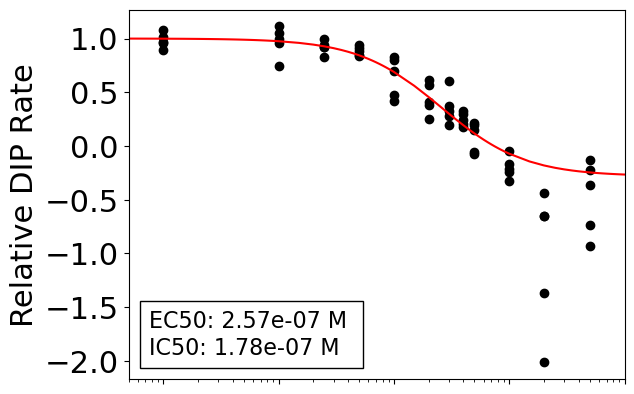

In [69]:
plot_dipplt(fig=fig, fp=fp)

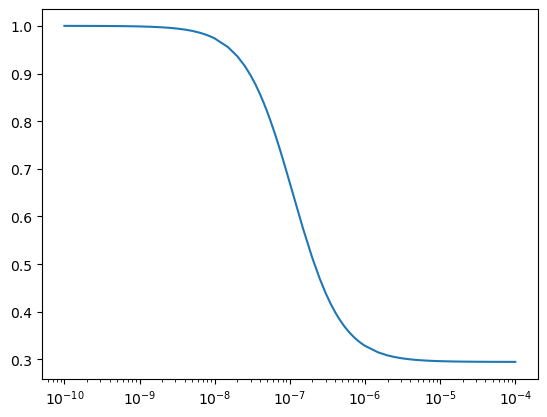

In [109]:
plt.plot(fig.data[0]['x'], fig.data[0]['y'])
# plt.scatter(fig.data[1]['x'], fig.data[1]['y'])
plt.xscale('log')

### CycBi 4kPa ERL

In [14]:
filepath = 'C:\\Users\\olesk\\ECM_mod_output\\cell_counts_bi_4kpa_erl.json'

fp = calc_resp(filepath, 'cycbi', wells=WELLS)

plot_drc(fp)

C:\Users\olesk\AppData\Local\Temp\ipykernel_21408\1520190320.py:26: FutureWarning:

The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.

C:\Users\olesk\anaconda3\envs\ECM_model\lib\site-packages\thunor\curve_fit.py:157: RuntimeWarning:

invalid value encountered in log

C:\Users\olesk\anaconda3\envs\ECM_model\lib\site-packages\thunor\curve_fit.py:224: RuntimeWarning:

invalid value encountered in scalar power



### CycDi 55kPa ERL

In [15]:
filepath = 'C:\\Users\\olesk\\ECM_mod_output\\cell_counts_di_55kpa_erl.json'

fp = calc_resp(filepath, 'cycdi', wells=WELLS)

plot_drc(fp)

C:\Users\olesk\AppData\Local\Temp\ipykernel_21408\1520190320.py:26: FutureWarning:

The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.

C:\Users\olesk\anaconda3\envs\ECM_model\lib\site-packages\thunor\curve_fit.py:157: RuntimeWarning:

invalid value encountered in log



In [256]:
name = filepath.split('\\')[-1].split('.')[0].split('_')[2:]

In [258]:
test = '_'.join(name)
test

'di_4kpa_erl'

In [234]:
all_treats = add_cond(all_treats, cell_counts_di, drug='cycDi')

C:\Users\olesk\AppData\Local\Temp\ipykernel_17972\1520190320.py:26: FutureWarning:

The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.



In [235]:
all_treats

,expt.id,expt.date,plate.name,well,cell.line,time,drug1,drug1.conc,drug1.units,cell.count,upid
0,1,2023-11-21,test,A01,DS8,0.000,cycDi,0.0000,M,11.0,test
1,1,2023-11-21,test,A01,DS8,0.201,cycDi,0.0000,M,12.0,test
2,1,2023-11-21,test,A01,DS8,0.401,cycDi,0.0000,M,13.0,test
3,1,2023-11-21,test,A01,DS8,0.702,cycDi,0.0000,M,14.0,test
4,1,2023-11-21,test,A01,DS8,2.609,cycDi,0.0000,M,15.0,test
...,...,...,...,...,...,...,...,...,...,...,...
4589,1,2023-11-21,test,M03,DS8,116.972,cycDi,0.0001,M,24.0,test
4590,1,2023-11-21,test,M03,DS8,117.692,cycDi,0.0001,M,25.0,test
4591,1,2023-11-21,test,M03,DS8,118.495,cycDi,0.0001,M,25.0,test
4592,1,2023-11-21,test,M03,DS8,119.298,cycDi,0.0001,M,25.0,test


In [236]:
all_treats.to_csv('C:\\Users\\olesk\\ECM_mod_output\\test.csv', index=False)

In [14]:
from thunor.io import read_vanderbilt_hts
hts007 = read_vanderbilt_hts('C:\\Users\\olesk\\ECM_mod_output\\test.csv')

HTS Dataset (1 drugs/combos, 1 cell lines)

In [10]:
from thunor.dip import dip_rates
from thunor.curve_fit import fit_params

In [220]:
hts007

HTS Dataset (1 drugs/combos, 1 cell lines)

In [239]:
ctrl_dip_data, expt_dip_data = dip_rates(hts007)

In [240]:
fp = fit_params(ctrl_dip_data, expt_dip_data)

In [11]:
from thunor.plots import plot_drc, plot_drc_params, plot_time_course, plot_ctrl_dip_by_plate, plot_plate_map

In [242]:
plot_drc(fp)

In [191]:
hts007_file = 'C:\\Users\\olesk\\anaconda3\\envs\\ECM_model\\Lib\\site-packages\\thunor\\hts007.h5'
hts007_filecsv = 'C:\\Users\\olesk\\Downloads\\gkab424_supplemental_files\\Data File S2 - hts007\\hts007.csv'

In [166]:
from thunor.io import read_hdf

In [212]:
hts007c = read_hdf(hts007_file)
#hts007csv = read_vanderbilt_hts(hts007_filecsv)

In [213]:
hts007c

HTS Dataset (27 drugs/combos, 8 cell lines)

In [168]:
hts007r = hts007c.filter(drugs=['cediranib', 'everolimus', 'paclitaxel'])

In [214]:
ctrl_dip_data, expt_dip_data = dip_rates(hts007r)
fp = fit_params(ctrl_dip_data, expt_dip_data)

C:\Users\olesk\anaconda3\envs\ECM_model\lib\site-packages\thunor\curve_fit.py:157: RuntimeWarning: invalid value encountered in log
  return c + (d - c) / (1 + np.exp(b * (np.log(x) - np.log(e))))
C:\Users\olesk\anaconda3\envs\ECM_model\lib\site-packages\thunor\curve_fit.py:224: RuntimeWarning: invalid value encountered in scalar power
  icN = self.ec50 * (ic_frac / (1 - ic_frac - (emax / e0))) ** (


In [217]:
type(expt_dip_data)

pandas.core.frame.DataFrame